# Spatial K-Fold Cross-validation

We perform spatial subsetting of the observed basal thermal state evidence and do cross-validation to find the optimal scale parameter for the Gaussian Process prior.

In [3]:
%reload_ext autoreload
%autoreload 2

import os
import sys
sys.path.append('../')
from pathlib import Path
import re
import numpy as np
from scipy.io import loadmat
import pandas as pd
import matplotlib.pyplot as plt
from gmr import GMM

# my inference model modules
from latentEnthalpyModel import BasalEvidence, PosteriorConfig
from Simulation import Simulation
from lowRankGPPrior import lowRankGPPrior
from GMMPrior import GMMPrior
from posteriorObjective import posteriorObjective

# clustering function
from utilities import cluster_points, build_masks_from_points

# Load data

In [4]:
data_path = "../data/"

# load simulations, grid, evidence masks, and pressure melting point
grid          = np.load(data_path + "grid.npz")
simulations   = np.load(data_path + "simulations.npz")
evidence_mask = np.load(data_path + "evidence_masks.npz")
pmp           = np.load(data_path + "pmp.npz")["pmp"]

# grid extent
extent_m  = [grid["x"].min(), grid["x"].max(), grid["y"].min(), grid["y"].max()]
extent_km = [x / 1e3 for x in extent_m]

# Standardization of simulation data

/home/donglaiyang/Documents/Georgia-Tech/Research/GMR-inference/src/Simulation.py:129: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


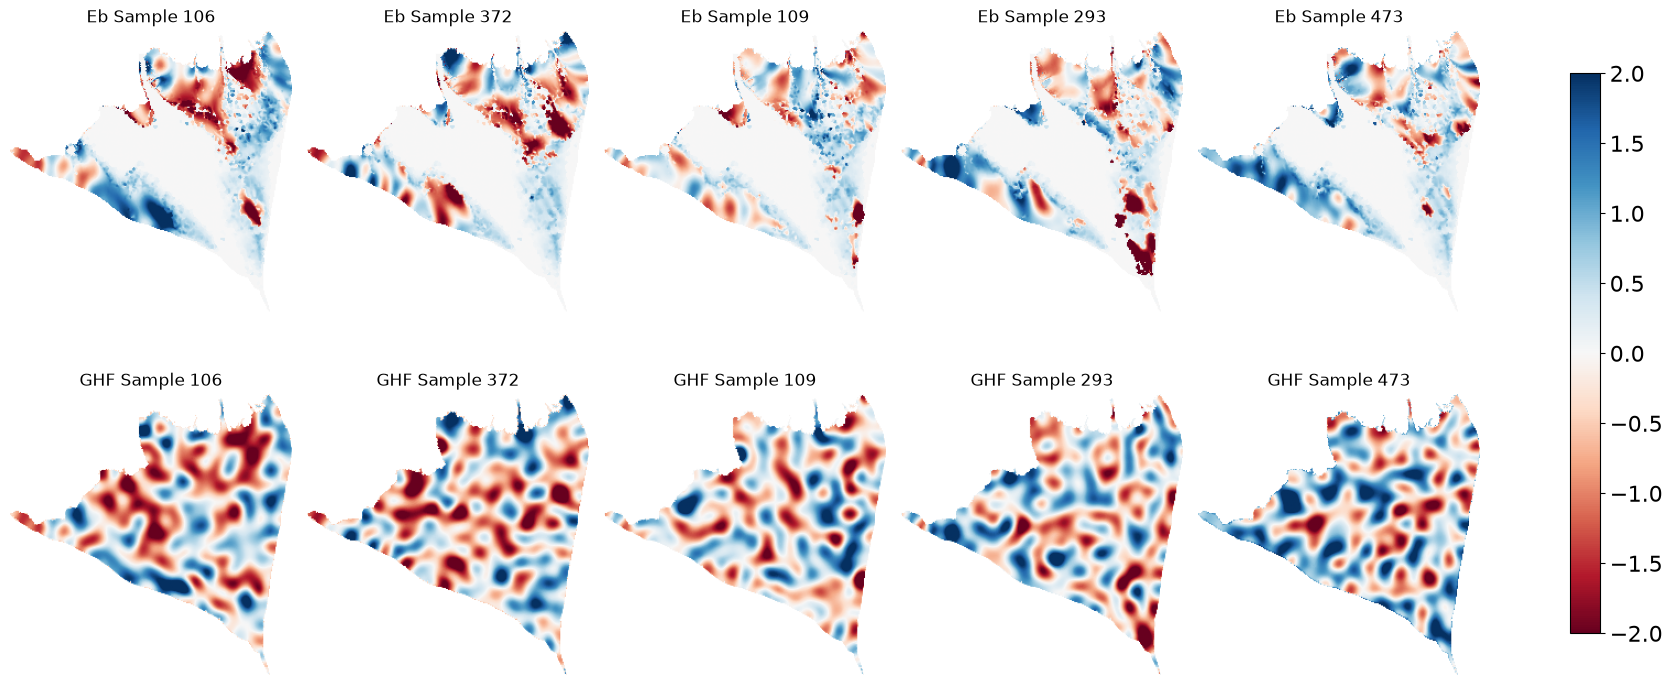

In [5]:
sims = Simulation(
    extent = extent_m,
    coord  = [grid["x"], grid["y"]]
)

sims.load_sim_data(
    X = [simulations["Eb"], simulations["GHF"]],
    labels = ["Eb", "GHF"],
    domain_mask = grid["mask"]
)

sims.show_data(n_samples_to_plot=5, savepath="../figs/ensemble_samples.png")

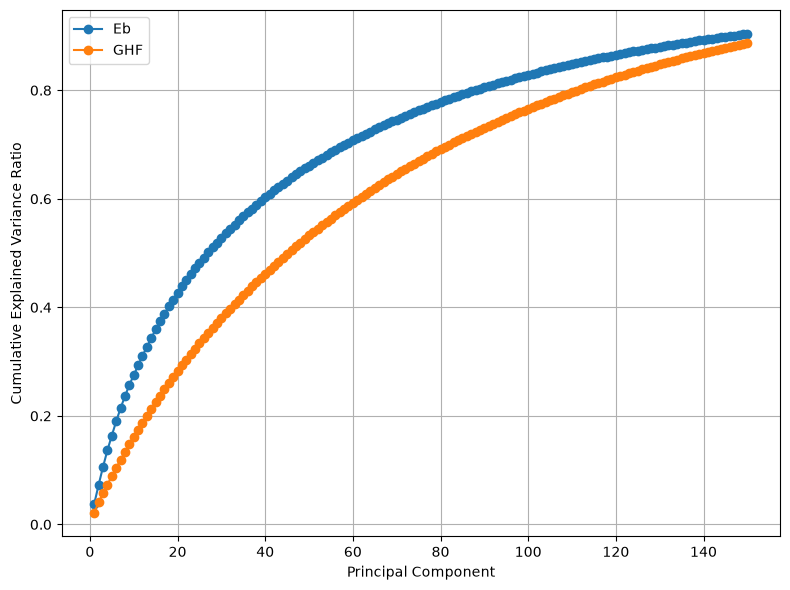

In [6]:
latent_spaces = [150, 150]

sims.find_reduction_model_pca(
    n_latent = latent_spaces,
    show_scree=True)

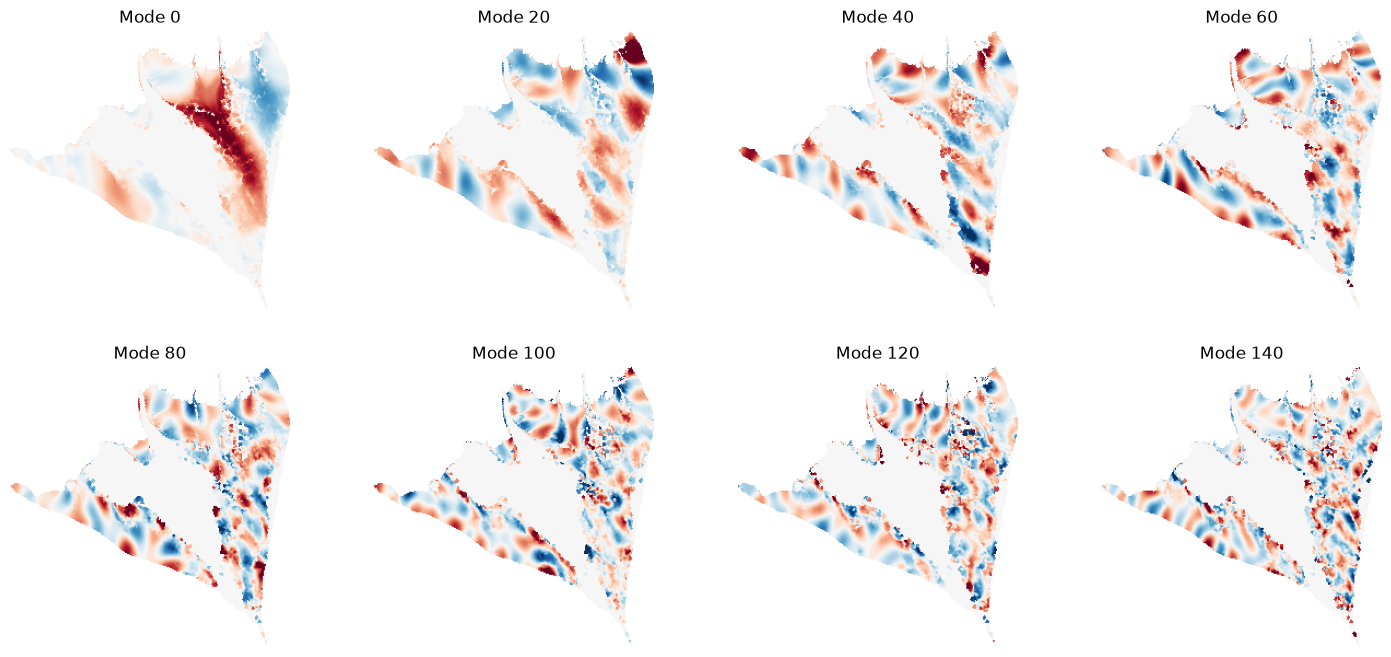

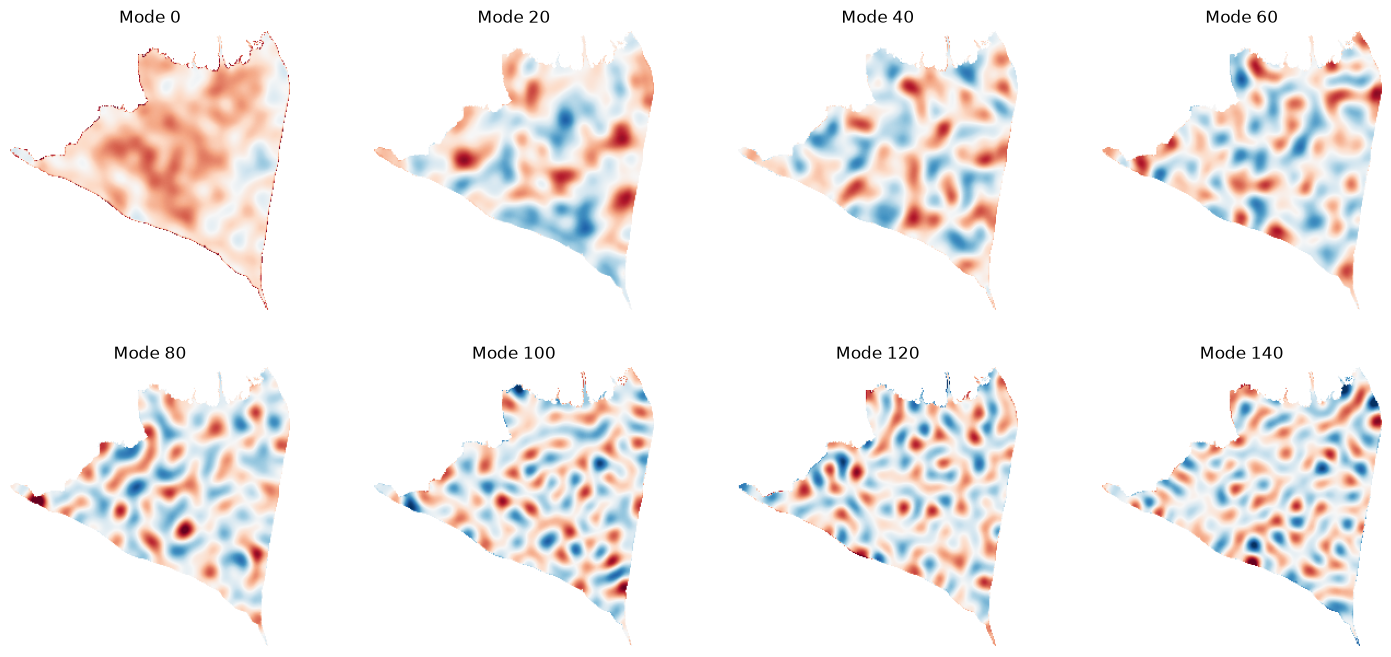

In [7]:
modes = range(0, sims.ndim_reduced[0], 20)
sims.show_mode(modes=modes, savepath="../figs/modes.png")

In [8]:
# split the data into training, validation, and test sets
sims.split_data(train_ratio=0.8, validation_ratio=0.1, test_ratio=0.1)

# This comes from the validation from the main inference file
gmm_n_gaussians = [2, 1]
sims.gmm_prior(n_gaussians = gmm_n_gaussians)

Splitting data: Total samples = 500
-------- Field 0: 
    Shape of X_train[0]: (400, 150)
    Shape of X_validation[0]: (50, 150)
    Shape of X_test[0]: (50, 150)
-------- Field 1: 
    Shape of X_train[1]: (400, 150)
    Shape of X_validation[1]: (50, 150)
    Shape of X_test[1]: (50, 150)
-----------------------------
-----------------------------
Fitting GMMs for each field
--------- Field 0, number of Gaussians: 2
--------- Field 1, number of Gaussians: 1


# Creating mixed prior

Step 1: Eigen-decomposition on graph Laplacian...
...Done.
Step 2: Get mode covariance under Matern kernel...
...Done.
Step 3: Projecting away and performing SVD...
...Done.


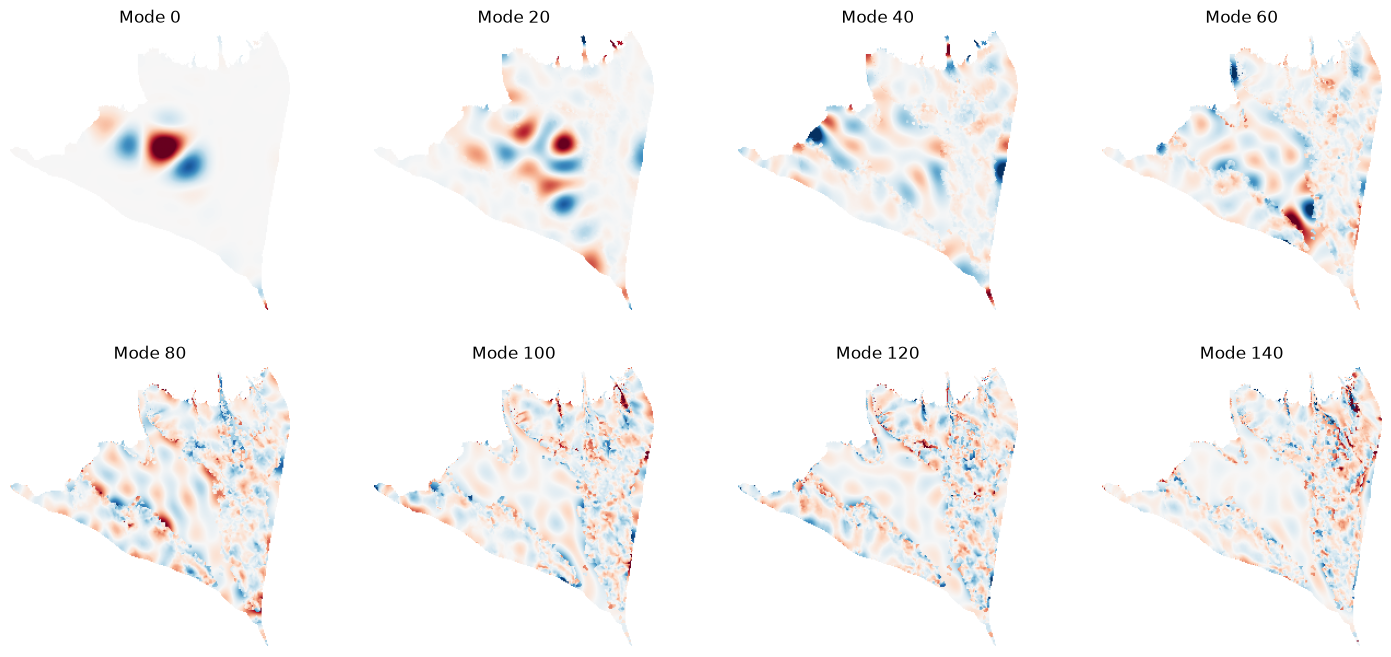

In [9]:
# prior distributions
gp_prior = lowRankGPPrior(
    domain_mask = sims.domain_mask,
    hx = sims.delta_x,
    hy = sims.delta_y,
    n_mode = 150,
    pca_basis = sims.pca_x[0].components_.T, # only look at Eb
    sigma_amp = 50,
    nu = 1,
    rho = 1, # 1
)

sim_prior = GMMPrior(
    gmm = sims.gmms[0]
)

gp_prior.plot_discrepancy_modes(modes=range(0, 150, 20), save_path="../figs/discrepancy_modes.png")

# Spatial clustering of evidence and subsetting

In [43]:
n_folds = 10
save_folder = "../data/spatial-cv/"

In [44]:
thawed_mask = evidence_mask["thawed_mask"] & ~evidence_mask["conflict_mask"]
frozen_mask = evidence_mask["frozen_mask"] & ~evidence_mask["conflict_mask"]
thawed_frac_area = np.where(thawed_mask, 1, 0)
frozen_frac_area = np.where(frozen_mask, 1, 0)

# get the coordinate of the pixelated evidence 
thawed_x = sims.X_grid.flatten()[thawed_mask.flatten() == 1]
frozen_x = sims.X_grid.flatten()[frozen_mask.flatten() == 1]
thawed_y = sims.Y_grid.flatten()[thawed_mask.flatten() == 1]
frozen_y = sims.Y_grid.flatten()[frozen_mask.flatten() == 1]
idx_thawed = np.where(thawed_mask.flatten() == 1)[0]
idx_frozen = np.where(frozen_mask.flatten() == 1)[0]
evidence_x = np.concatenate([thawed_x, frozen_x])
evidence_y = np.concatenate([thawed_y, frozen_y])
print("shape of evidence_x:", evidence_x.shape)
print("shape of evidence_y:", evidence_y.shape)


# CLUSTER ALL EVIDENCE INTO 50 GROUPS
cluster_labels, cluster_centroids, cluster_groups = cluster_points(
    evidence_x, evidence_y, n=50, show_plot=False
)

# SPLIT: 5 HOLDOUT CLUSTERS vs 45 TRAINING CLUSTERS 
n_ppc_clusters = 8
np.random.seed(42)
ppc_cluster_indices = set(np.random.choice(50, size=n_ppc_clusters, replace=False))
train_cluster_indices = [i for i in range(50) if i not in ppc_cluster_indices]

print("Holdout cluster indices (PPC):", sorted(ppc_cluster_indices))
print("Training cluster indices     :", train_cluster_indices)



shape of evidence_x: (868,)
shape of evidence_y: (868,)
Holdout cluster indices (PPC): [np.int64(13), np.int64(17), np.int64(25), np.int64(26), np.int64(30), np.int64(39), np.int64(45), np.int64(48)]
Training cluster indices     : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 14, 15, 16, 18, 19, 20, 21, 22, 23, 24, 27, 28, 29, 31, 32, 33, 34, 35, 36, 37, 38, 40, 41, 42, 43, 44, 46, 47, 49]


In [46]:
# build thawed/frozen masks from a list of (x,y) points 
flat_x = sims.X_grid.flatten()
flat_y = sims.Y_grid.flatten()
grid_shape = (sims.X_grid.shape[0], sims.X_grid.shape[1])

# BUILD HOLDOUT (PPC) MASKS 
ppc_points = [pt for i in ppc_cluster_indices for pt in cluster_groups[i]]

ppc_thawed_mask, ppc_frozen_mask = build_masks_from_points(
    ppc_points, idx_thawed, idx_frozen, flat_x, flat_y, grid_shape
)

ppc_thawed_area = np.zeros_like(ppc_thawed_mask, dtype=float)
ppc_frozen_area = np.zeros_like(ppc_frozen_mask, dtype=float)
ppc_thawed_area[ppc_thawed_mask] = 1.0
ppc_frozen_area[ppc_frozen_mask] = 1.0

ppc_evidence_mask = {
    "ppc_thawed_mask" : ppc_thawed_mask,
    "ppc_frozen_mask" : ppc_frozen_mask
}
ppc_evidence_area = {
    "ppc_thawed_area" : ppc_thawed_area,
    "ppc_frozen_area" : ppc_frozen_area
}

print("PPC thawed points :", ppc_thawed_mask.sum())
print("PPC frozen points :", ppc_frozen_mask.sum())


PPC thawed points : 97
PPC frozen points : 42


In [47]:
# BUILD TRAINING (45-CLUSTER) MASKS 
train_points = [pt for i in train_cluster_indices for pt in cluster_groups[i]]

train_thawed_mask, train_frozen_mask = build_masks_from_points(
    train_points, idx_thawed, idx_frozen, flat_x, flat_y, grid_shape
)

print("Training thawed points:", train_thawed_mask.sum())
print("Training frozen points:", train_frozen_mask.sum())


Training thawed points: 522
Training frozen points: 207


In [48]:
# RE-CLUSTER TRAINING POINTS INTO 10 CV FOLDS
train_x = flat_x[train_thawed_mask.flatten() | train_frozen_mask.flatten()]
train_y = flat_y[train_thawed_mask.flatten() | train_frozen_mask.flatten()]

cv_labels, cv_centroids, cv_groups = cluster_points(
    train_x, train_y, n=n_folds, show_plot=False
)

# BUILD 10 SETS OF (thawed_mask, frozen_mask) FOR CV FOLDS
cv_masks = []  # list of 10 dicts, each with 'train' and 'val' masks
cv_areas = []  # fractional area


In [53]:

for fold_idx in range(n_folds):
    val_points   = cv_groups[fold_idx]
    train_fold_points = [pt for j, pts in cv_groups.items()
                         if j != fold_idx for pt in pts]

    val_thawed,   val_frozen   = build_masks_from_points(
        val_points, idx_thawed, idx_frozen, flat_x, flat_y, grid_shape
    )
    train_thawed, train_frozen = build_masks_from_points(
        train_fold_points, idx_thawed, idx_frozen, flat_x, flat_y, grid_shape
    )

    cv_masks.append({
        "fold"         : fold_idx,
        "val_thawed"   : val_thawed,
        "val_frozen"   : val_frozen,
        "train_thawed" : train_thawed,
        "train_frozen" : train_frozen,
    })

    val_thawed_area = np.zeros_like(val_thawed, dtype=float)
    val_frozen_area = np.zeros_like(val_frozen, dtype=float)
    val_thawed_area[val_thawed] = 1.0
    val_frozen_area[val_frozen] = 1.0
    train_thawed_area = np.zeros_like(train_thawed, dtype=float)
    train_frozen_area = np.zeros_like(train_frozen, dtype=float)
    train_thawed_area[train_thawed] = 1.0
    train_frozen_area[train_frozen] = 1.0
    cv_areas.append({
        "fold"         : fold_idx,
        "val_thawed_area"   : val_thawed_area,
        "val_frozen_area"   : val_frozen_area,
        "train_thawed_area" : train_thawed_area,
        "train_frozen_area" : train_frozen_area,
    })

    print(f"Fold {fold_idx:2d} | "
          f"train thawed={train_thawed.sum():4d}  frozen={train_frozen.sum():4d} | "
          f"val   thawed={val_thawed.sum():4d}  frozen={val_frozen.sum():4d}")

# save PPC masks and areas
ppc_save_folder = save_folder
os.makedirs(ppc_save_folder, exist_ok=True)
np.savez(ppc_save_folder + "ppc_evidence_masks.npz", **ppc_evidence_mask)
np.savez(ppc_save_folder + "ppc_evidence_areas.npz", **ppc_evidence_area)
print(f"PPC evidence masks and areas saved to {ppc_save_folder}")

cv_save_folder = save_folder
os.makedirs(cv_save_folder, exist_ok=True)
for fold_idx in range(n_folds):
    fold_masks = cv_masks[fold_idx]
    fold_areas = cv_areas[fold_idx]
    np.savez(cv_save_folder + f"cv_fold_{fold_idx}_masks.npz", **fold_masks)
    np.savez(cv_save_folder + f"cv_fold_{fold_idx}_areas.npz", **fold_areas)
print(f"CV fold masks and areas saved to {cv_save_folder}")


Fold  0 | train thawed= 465  frozen= 185 | val   thawed=  57  frozen=  22
Fold  1 | train thawed= 492  frozen= 207 | val   thawed=  30  frozen=   0
Fold  2 | train thawed= 494  frozen= 207 | val   thawed=  28  frozen=   0
Fold  3 | train thawed= 370  frozen= 121 | val   thawed= 152  frozen=  86
Fold  4 | train thawed= 470  frozen= 182 | val   thawed=  52  frozen=  25
Fold  5 | train thawed= 481  frozen= 207 | val   thawed=  41  frozen=   0
Fold  6 | train thawed= 508  frozen= 179 | val   thawed=  14  frozen=  28
Fold  7 | train thawed= 427  frozen= 161 | val   thawed=  95  frozen=  46
Fold  8 | train thawed= 493  frozen= 207 | val   thawed=  29  frozen=   0
Fold  9 | train thawed= 498  frozen= 207 | val   thawed=  24  frozen=   0
PPC evidence masks and areas saved to ../data/spatial-cv/
CV fold masks and areas saved to ../data/spatial-cv/


# Make the plot!

In [55]:
# visualize the cv masks
def plot_folds(cv_masks, flat_x, flat_y, figsize=(24, 12), save_path=None):
    """
    Plot all 10 CV folds as subplots.
    Each subplot shows:
        - Grey  : points not in this fold's train or val set (PPC holdout)
        - Blue  : training points for this fold
        - Red   : validation points for this fold
        - Green : thawed points
        - Orange: frozen points
    """
    n_folds = len(cv_masks)
    ncols = 5
    nrows = (n_folds + ncols - 1) // ncols 

    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    axes = axes.flatten()

    # bring x and y to km
    flat_x = flat_x / 1000
    flat_y = flat_y / 1000

    for fold_idx, fold in enumerate(cv_masks):
        ax = axes[fold_idx]

        train_thawed = fold["train_thawed"].flatten()
        train_frozen = fold["train_frozen"].flatten()
        val_thawed   = fold["val_thawed"].flatten()
        val_frozen   = fold["val_frozen"].flatten()

        # ── plot training points ──────────────────────────────────────────
        ax.scatter(
            flat_x[train_thawed], flat_y[train_thawed],
            c="steelblue", s=8, alpha=0.6, label="Train – Thawed"
        )
        ax.scatter(
            flat_x[train_frozen], flat_y[train_frozen],
            c="cornflowerblue", s=8, alpha=0.6, marker="s", label="Train – Frozen"
        )

        # ── plot validation points ────────────────────────────────────────
        ax.scatter(
            flat_x[val_thawed], flat_y[val_thawed],
            c="tomato", s=18, alpha=0.9, zorder=3, label="Validate – Thawed"
        )
        ax.scatter(
            flat_x[val_frozen], flat_y[val_frozen],
            c="firebrick", s=18, alpha=0.9, zorder=3, marker="s", label="Validate – Frozen"
        )
        # add the drainage boundary points
        for x,y in sims.domain_bound_line:
            ax.plot(x/1e3, y/1e3, 'k.', markersize=1)

        n_train = train_thawed.sum() + train_frozen.sum()
        n_val   = val_thawed.sum()   + val_frozen.sum()

        ax.set_title(f"Fold {fold_idx}  |  train={n_train}  validate={n_val}",
                     fontsize=15)
        ax.set_xlabel("X (km)", fontsize=12)
        ax.set_ylabel("Y (km)", fontsize=12)
        ax.tick_params(labelsize=10)
        ax.set_aspect("equal", adjustable="box")

    for j in range(n_folds, len(axes)):
        axes[j].set_visible(False)

    legend_handles = [
        mpatches.Patch(color="steelblue",      label="Train – Thawed"),
        mpatches.Patch(color="cornflowerblue", label="Train – Frozen"),
        mpatches.Patch(color="tomato",         label="Validate – Thawed"),
        mpatches.Patch(color="firebrick",      label="Validate – Frozen"),
    ]
    fig.legend(
        handles=legend_handles,
        loc="lower center",
        ncol=4,
        fontsize=18,
        frameon=True,
        bbox_to_anchor=(0.5, 0.01)
    )

    fig.suptitle("K-Fold CV Splits (10 Folds) — Spatial Clusters",
                 fontsize=18, fontweight="bold", y=1.01)
    plt.tight_layout(rect=[0, 0.05, 1, 1])
    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
        print(f"CV fold plot saved to {save_path}")

CV fold plot saved to ../figs/cv_masks.png
PPC holdout plot saved to ../figs/ppc_holdout.png


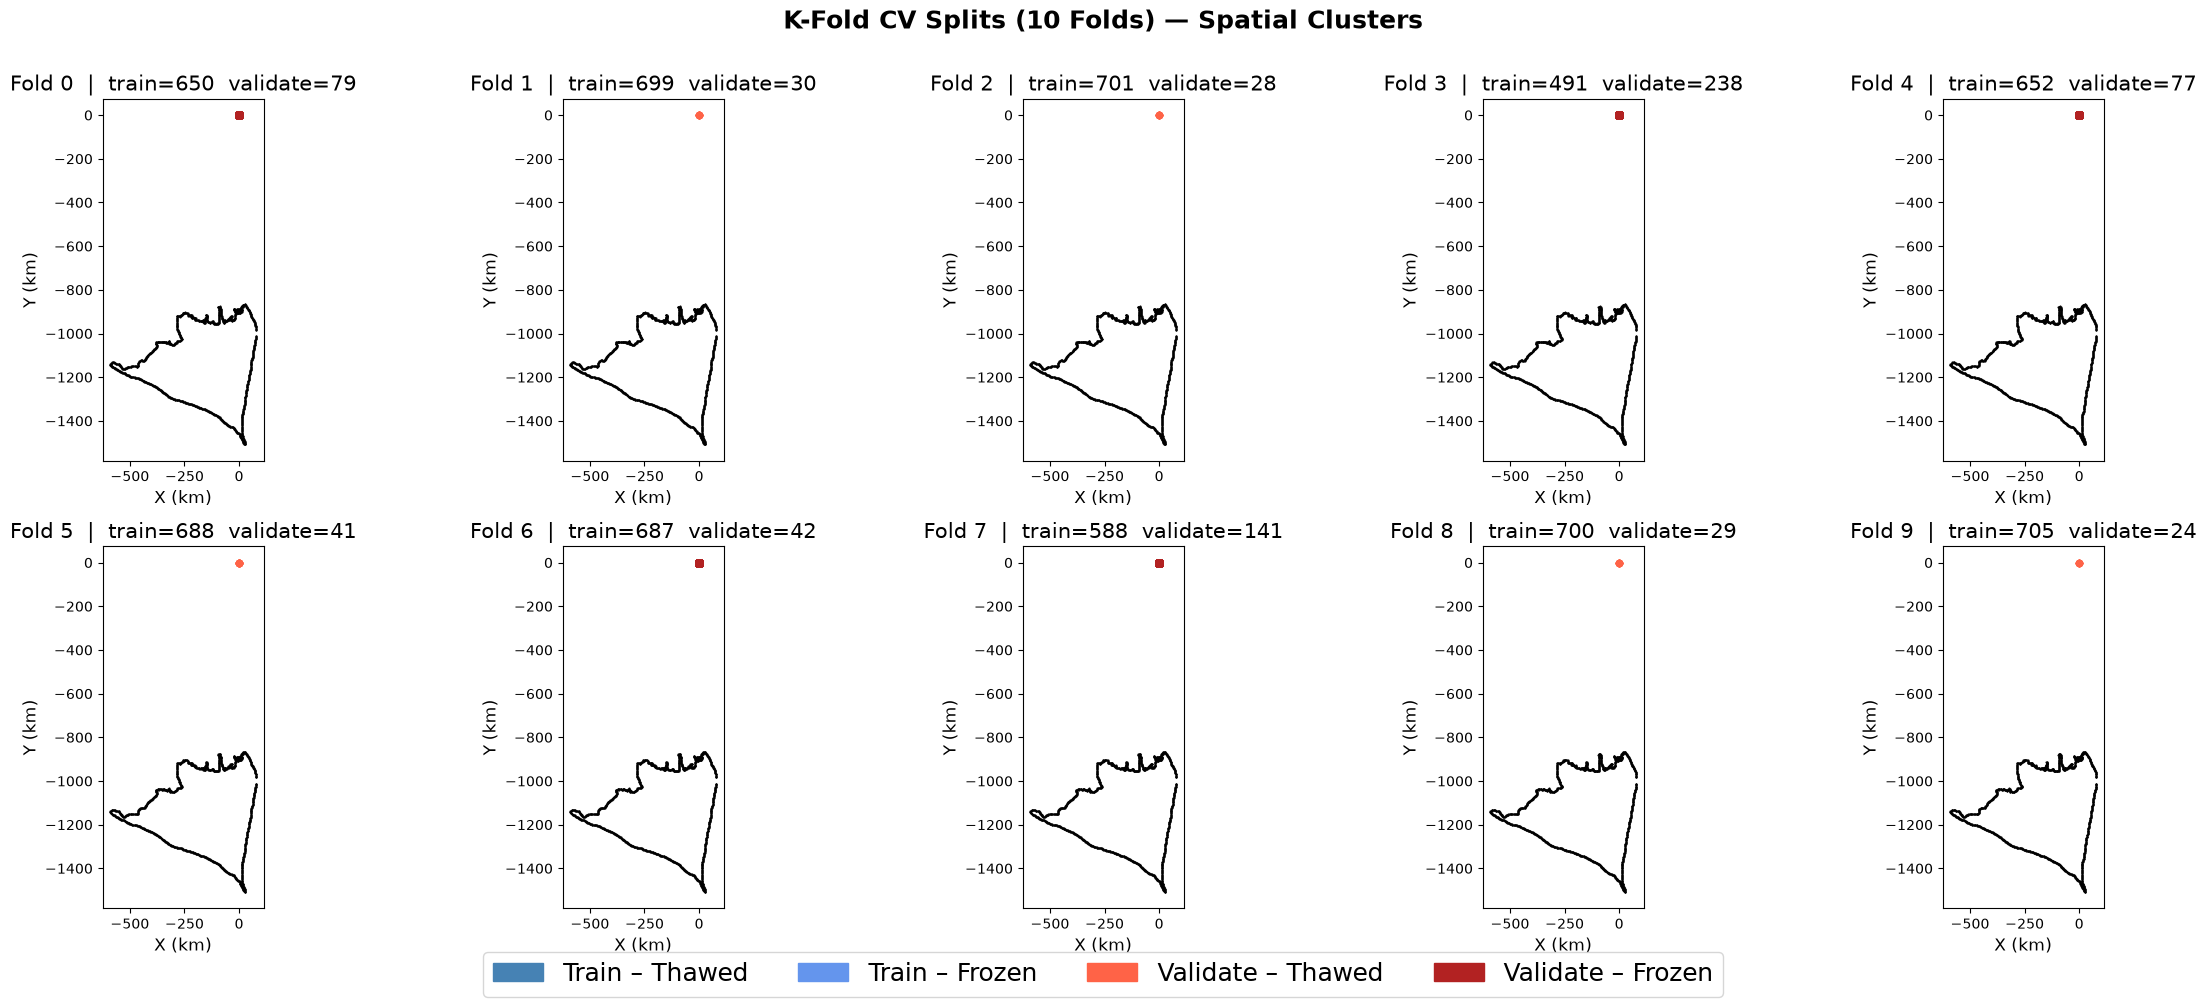

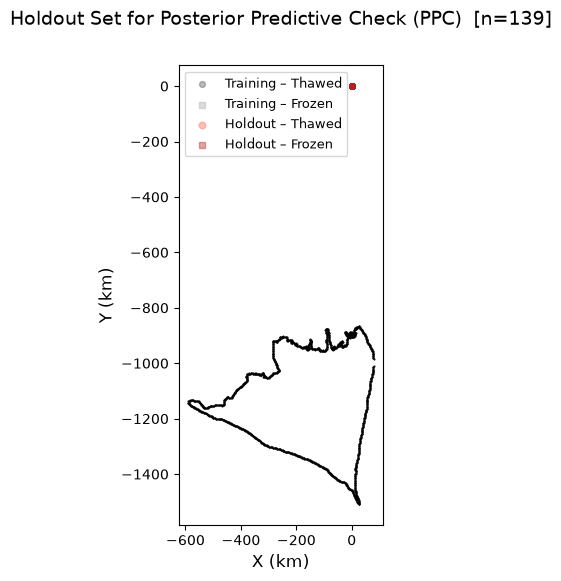

In [ ]:
import matplotlib.patches as mpatches

flat_x_km = flat_x / 1000
flat_y_km = flat_y / 1000
plot_folds(cv_masks,  
           flat_x_km,  flat_y_km, 
           figsize=(24, 10),
           save_path="../figs/cv_masks.png")

# Visualize the holdout dataset, with the K-fold datasets grayed out in the background
fig, ax = plt.subplots(1, 1, figsize=(6, 6))
ppc_thawed = ppc_evidence_mask["ppc_thawed_mask"].flatten()
ppc_frozen  = ppc_evidence_mask["ppc_frozen_mask"].flatten()

# ── non-holdout points (grey background) ─────────────────────────────────────
# thawed that are NOT in holdout → dark grey
bg_thawed = idx_thawed[~ppc_thawed[idx_thawed]]
# frozen that are NOT in holdout → light grey
bg_frozen  = idx_frozen[~ppc_frozen[idx_frozen]]

ax.scatter(
    flat_x_km[bg_thawed], flat_y_km[bg_thawed],
    c="#555555", s=8, alpha=0.4, zorder=1, label="Training – Thawed"
)
ax.scatter(
    flat_x_km[bg_frozen], flat_y_km[bg_frozen],
    c="#aaaaaa", s=8, alpha=0.4, zorder=1, marker="s", label="Training – Frozen"
)

# ── holdout points (coloured foreground) ─────────────────────────────────────
ax.scatter(
    flat_x_km[ppc_thawed], flat_y_km[ppc_thawed],
    c="tomato", s=10, alpha=0.4, zorder=3, label="Holdout – Thawed"
)
ax.scatter(
    flat_x_km[ppc_frozen], flat_y_km[ppc_frozen],
    c="firebrick", s=10, alpha=0.4, zorder=3, marker="s", label="Holdout – Frozen"
)
for x,y in sims.domain_bound_line:
    ax.plot(x/1e3, y/1e3, 'k.', markersize=1)
# ── formatting ────────────────────────────────────────────────────────────────
n_ppc = ppc_thawed.sum() + ppc_frozen.sum()

ax.set_xlabel("X (km)", fontsize=12)
ax.set_ylabel("Y (km)", fontsize=12)
ax.tick_params(labelsize=10)
ax.set_aspect("equal", adjustable="box")
ax.legend(fontsize=9, markerscale=1.5, framealpha=0.8)

fig.suptitle(f"Holdout Set for Posterior Predictive Check (PPC)  [n={n_ppc}]",
             fontsize=14, y=1.01)
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig("../figs/ppc_holdout.png", dpi=300, bbox_inches="tight")
print(f"PPC holdout plot saved to ../figs/ppc_holdout.png")